### 本册学什么（导读）
这本笔记本是《Raman.ipynb》的进阶版：不再只处理一条光谱，而是**批量处理一个文件夹里的 8 条拉曼光谱**。
流程：① 导入通用包 → ② 用 os.walk 批量读取数据文件夹，把每条光谱整理成表格中的一"行" → ③ 定义并调用平滑函数（Savitzky–Golay）→ ④ airPLS 基线校正（并比较"先平滑再基线"与"先基线再平滑"两种顺序）→ ⑤ 归一化。
你将顺带学到三个实用技巧：批量遍历文件与合并表格（pandas.concat）、把常用处理封装成函数（def）、多条曲线"错开画图"（dy 偏移）。

# 演示多Raman数据文件

# 步骤1：导入该实验所需的通用包
使用到的通用包有：***NumPy***、***Matplotlib*** 

In [1]:
# 导入 numpy 数值计算库（习惯简写 np），用来处理数组/向量
import numpy as np
# 导入 matplotlib 的 pyplot 画图模块（习惯简写 plt）
import matplotlib.pyplot as plt
# 设置画图中文字体为宋体，否则图里的中文会显示成方框
plt.rcParams['font.sans-serif'] = ['SimSun'] # 用来正常显示中文标签
# os模块是与操作系统交互的模块，用来操作文件

# 步骤2：导入原始数据

### 2.1 导入原始数据
原始数据的存储格式为.txt文件，其中前43行为仪器参数相关信息(因此读入数据时应略去)，第44行后的第一列指的是拉曼位移，第二列指的是拉曼强度。  

In [35]:
# 导入 pandas 表格数据处理库（习惯简写 pd）
import pandas as pd
# "./data" 表示当前 notebook 所在目录下的 data 子文件夹，里面放着 8 个光谱数据文件
directory_path = "./data"   # 此处是相对路径，也可用绝对路径，比如 r"E:\JS\785nm-1200G"

# 建一个空列表，用来存放每个文件处理好的表格
pools = []
# 遍历目录及其子目录
# os.walk() 遍历目录及子目录，返回三元组（目录路径，目录名列表，文件名列表）
for folder_name, sub_folders, filenames in os.walk(directory_path):  # os.walk() 遍历目录及子目录，返回三元组（目录路径，目录名列表，文件名列表）
    # 内层 for 循环：逐个取出该目录下的每个文件名
    for filename in filenames:
        # 拼接出文件全路径
        file_path = os.path.join(folder_name, filename)  # 拼接出文件全路径

        # skiprows: 略过多少行， encoding：文件编码
        # 读取单个文件：delimiter='\t' 制表符分隔、header=None 无表头、skiprows=43 跳过开头的仪器参数
        df =  pd.read_csv(file_path, delimiter='\t', header=None, skiprows=43, encoding='ISO-8859-1')  # skiprows: 略过多少行， encoding：文件编码
        # df = pd.read_csv(file_path, header=None)

        # 把df的第1列设为index（此时原本两列，一列成了index，因此只剩下一列数据）并转置，转置后实际上index成了column且一列数据变成一行数据
        dt = df.set_index(0).T
        # 保留4位小数
        dt = dt.round(4)  # 保留4位小数

        # 下面两个新增列的根据实际情况而定是否需要
        # 用额外的列class保存文件名（一般文件名上含有标记或浓度等重要信息）
        # os.path.basename 取出文件名，splitext 把"文件名.扩展名"拆开并取前半段
        dt['class'] = os.path.splitext(os.path.basename(filename))[0]  # 用额外的列class保存文件名（一般文件名上含有标记或浓度等重要信息）
        # 用列data_type保存文件全路径
        rel_path = file_path
        dt['data_type'] = rel_path  # 用列data_type保存文件全路径

        # 把循环中处理好的单个文件数据保存到pools中
        # append() 把这张表追加到列表末尾
        pools.append(dt) # 把循环中处理好的单个文件数据保存到pools中

# if 判断：只要读到了至少一个文件，就把它们合并成一张表
if len(pools) > 0:
    # concat 把列表里的表上下拼接；ignore_index=True 表示重新编行号
    result = pd.concat(pools, ignore_index=True)  # 把pools中数据重新融合成一个完整的dataframe

# 单元格最后一行只写变量名，运行后自动显示合并结果
result

,200.052,201.312,202.571,203.83,205.088,206.346,207.604,208.862,210.119,211.376,...,1793.39,1794.26,1795.13,1796.0,1796.88,1797.75,1798.62,1799.49,class,data_type
0,128.9310,130.5170,132.8620,134.3100,131.5520,130.2410,131.8280,135.5520,135.8280,133.0000,...,88.0345,86.7931,87.2069,86.7931,86.9310,85.8966,87.5517,87.4138,WS-23-实际-0-5,./data\WS-23-实际-0-5.txt
1,140.7930,142.7930,143.2070,146.4480,145.7590,144.2410,142.8620,145.3450,145.6210,146.5860,...,89.4828,87.6207,87.3448,85.9655,86.4483,86.5172,83.0000,83.5517,WS-23-实际-1-0,./data\WS-23-实际-1-0.txt
2,137.7590,136.3100,140.2410,141.4830,138.5170,140.4480,141.6900,138.7240,142.6550,139.7590,...,90.2414,92.3793,93.5517,90.5173,93.1379,93.9655,91.9655,92.7241,WS-23-实际-3-0,./data\WS-23-实际-3-0.txt
3,145.6210,143.8970,148.2410,148.1720,148.5170,149.3450,150.5860,151.1380,150.0350,153.6210,...,85.8276,88.0345,87.1379,87.0000,84.3103,87.0000,87.7586,86.9310,WS-23-实际-5-0,./data\WS-23-实际-5-0.txt
4,148.1030,147.8970,154.0340,152.0340,149.6900,148.3100,155.2760,152.8620,156.7240,154.7240,...,88.5173,87.4828,88.8621,90.3103,88.7931,88.2414,86.8621,88.5172,WS-23-实际-8-0,./data\WS-23-实际-8-0.txt
5,82.5862,77.0000,84.0345,83.3448,82.3103,84.5172,81.4138,85.2069,82.2414,82.8621,...,74.1034,75.3448,74.9310,73.9655,73.8966,74.4483,72.7241,71.6207,WS-23-模拟-0-5,./data\WS-23-模拟-0-5.txt
6,81.8966,79.2069,85.7586,84.8621,83.6897,84.1724,84.2414,85.6897,85.4828,86.3793,...,69.9655,71.1379,70.3793,67.7586,68.6552,68.8621,70.5862,68.2414,WS-23-模拟-1-0,./data\WS-23-模拟-1-0.txt
7,85.4138,81.3448,85.1379,86.6552,86.4483,84.3103,86.1724,83.3448,84.4483,85.8276,...,75.0690,77.7586,75.8966,74.9310,74.5862,77.4138,73.8965,75.0000,WS-23-模拟-10-0,./data\WS-23-模拟-10-0.txt
8,86.2414,85.8276,89.4138,86.3793,88.7241,86.5862,84.7931,88.7931,83.9655,88.0345,...,81.0000,79.6897,79.4138,81.4828,78.2414,78.9310,77.7586,79.7586,WS-23-模拟-3-0,./data\WS-23-模拟-3-0.txt
9,82.2414,81.3448,85.9655,86.7241,85.1379,88.0345,83.7586,88.7241,86.6552,87.8276,...,72.2414,71.7586,70.7242,72.7931,72.5862,73.6896,71.4138,71.8966,WS-23-模拟-5-0,./data\WS-23-模拟-5-0.txt


## 2.2 拉曼光谱数据的向量表示及可视化
首先将数据转换为array数组形式，再分别取出以向量的形式表示的拉曼位移数据（光谱图的横轴）和其对应的拉曼强度数据（光谱图的纵轴）。

In [4]:
# iloc是dataframe的切片操作，纯数据部分不包括最后两列(前面额外新增的class与data_type两列)
# [:, :-2] 表示"取所有行、列取到倒数第 3 个为止"——把 class 和 data_type 两列丢掉，只留纯光谱数据
data = result.iloc[:, :-2]  # iloc是dataframe的切片操作，纯数据部分不包括最后两列(前面额外新增的class与data_type两列)
# x轴实际就是dataframe的columns，见上
# columns 是列名（即各拉曼位移值），直接拿来当 x 轴
x = data.columns  # x轴实际就是dataframe的columns，见上
# 多样本的y轴实际就是dataframe的values，见上
# values 取出全部数字，得到 8 行 × N 列的数组——每行就是一条光谱
ys = data.values  # 多样本的y轴实际就是dataframe的values，见上

## 2.3 根据x轴和y轴数据，绘制原始拉曼光谱图。

In [5]:
# def 定义一个画图函数；labels, dy两个参数有缺省值
# "缺省值"=调用时可以不传这两个参数（不传就用默认值 labels=None、dy=0.1）
def plot_spectra(x, ys, title, labels=None, dy=0.1):  # labels, dy两个参数有缺省值
  """
  x: x轴坐标
  ys: y轴坐标，支持一条光谱数据(1D数组)与多条数据(2D数组)
  title: 图的标题
  labels：每条数据的标签
  dy: 多条数光谱数据偏移高度，主要目的是不使数据的谱线重合
  """
  # isinstance() 判断 ys 是不是 numpy 数组；len(ys.shape)==1 说明只有一条光谱
  if isinstance(ys, np.ndarray) and len(ys.shape) == 1:
      # 使ys为2D数组
      # 用外面包一层 [] 的方法，把一条光谱变成"一行多条"，后面可以统一处理
      ys = np.array([ys])  # 使ys为2D数组

  # 新建画布
  plt.figure(figsize=(10,6))
  # 如果没传x轴坐标，则使用最后一个维度上的数组序号作为x轴坐标
  if x is None:  # 如果没传x轴坐标，则使用最后一个维度上的数组序号作为x轴坐标
      x = np.array(list(range(ys.shape[-1])))

  # for 循环 + enumerate：逐条取出光谱并画图，i 是当前条数编号（0,1,2...）
  for i, y in enumerate(ys):
      # 如果有传labels则作图时使用label
      # 关键技巧 y + dy*i：第 i 条曲线整体向上抬 dy*i，让多条曲线错开、互不重叠
      if labels is not None and len(labels) > 0:  # 如果有传labels则作图时使用label
          plt.plot(x, y + dy * i, label=labels[i])
      else:
          plt.plot(x, y + dy * i)
  plt.xlabel('位移(cm$^{-1}$)')
  plt.ylabel('强度(a.u.)')
  plt.title(title)
  # 如果有传labels则作图时显示出label
  if labels is not None and len(labels) > 0:  # 如果有传labels则作图时显示出label
    plt.legend()
  plt.show()

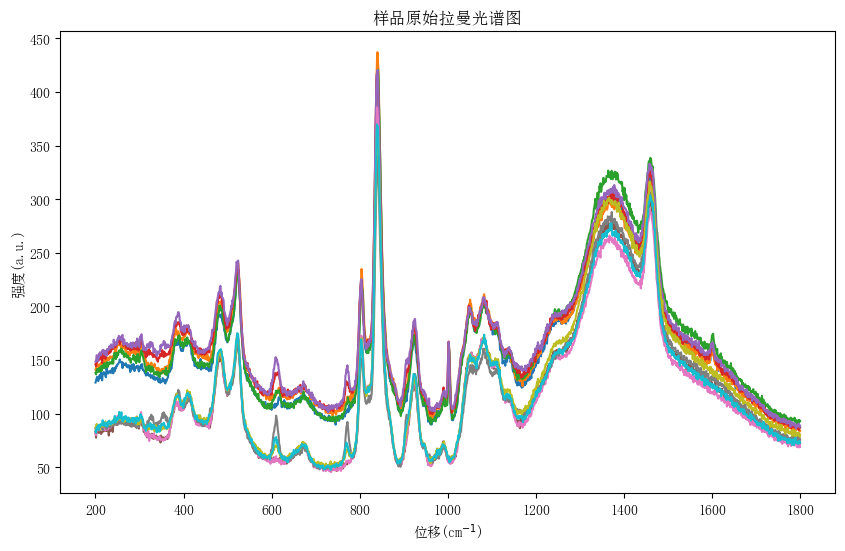

In [6]:
# 调用刚定义的画图函数，把全部原始光谱画出来
plot_spectra(x, ys, '样品原始拉曼光谱图')  # 原始数据少，只有8条，因此全show。

# 如果原始数据特别多，应该只show前5条. 此时可以用在函数调用时只传前5条数据 ys[:5]
# plot_spectra(x, ys[:5], '样品原始拉曼光谱图')

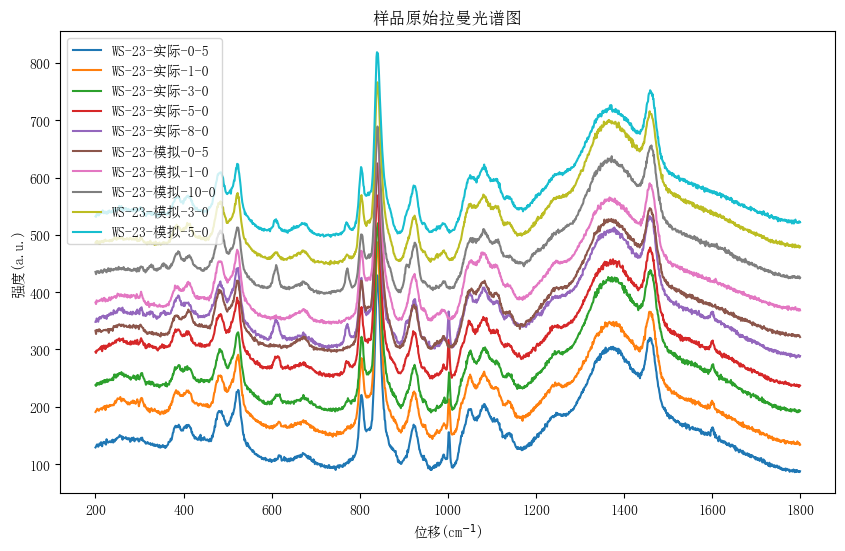

In [14]:
# dy=50：第 i 条曲线抬高 50*i，8 条光谱从上到下错开排列（像"瀑布"一样），解决上图重叠问题
plot_spectra(x, ys, '样品原始拉曼光谱图', dy=50)  #  上图原始数据有重叠，可以每条谱图增加一个增量（比如 dy=50)

# 可以试一下下面的给出labels的效果
# plot_spectra(x, ys, '样品原始拉曼光谱图', labels=result.iloc[:, -2], dy=50)  # result.iloc[:, -2]是result这个dataframe的倒数第二列(实际就是class那一列)

# 步骤3：平滑去噪
### 3.1 窗口移动平均法


### 批量处理的思路：先把"工具"封装成函数
与单条光谱不同，这里一次要处理 8 条光谱。Python 的做法是：先用 def 把"平滑""基线校正"写成**函数**，之后对每条数据重复调用即可，一行代码就能批量完成，避免把同样的代码复制粘贴 8 遍。
本节先定义平滑函数 sg_smooth（Savitzky–Golay 法：窗口 11、三次多项式）；基线校正函数 airpls_baseline 也在这里一并定义好，留给下一步骤使用。

In [20]:
# 导入 Savitzky–Golay 平滑滤波函数
from scipy.signal import savgol_filter
# 导入 pybaselines 的 Baseline 模块（含 airPLS 基线校正算法，下一步骤使用）
from pybaselines import Baseline


# 定义批量平滑函数：传入多条光谱，一次全部平滑
def sg_smooth(ys):
    # 定义窗口大小（必须是奇数）
    window_size = 11

    # 定义多项式的阶数
    polyorder = 3

    # 使用savgol_filter函数计算窗口移动多项式平滑
    # savgol_filter 本身就支持一次处理多条光谱（对每一行分别平滑）
    ysn = savgol_filter(ys, window_length=window_size, polyorder=polyorder)
    # return 把平滑结果返回给调用者
    return ysn


# 定义批量基线校正函数：逐条做 airPLS
def airpls_baseline(ys, x=None):
    # Baseline对象需要x轴坐标, 此时利用ys数组最后一个维度的长度(Feature的个数)生成了一个伪坐标[0, 1, 2, ..., ]
    # (由于Raman中波数基本等间隔，因此这个坐标与实际坐标线性一一映射)
    if x is None:
        x = list(range(ys.shape[-1]))
    baseline_fitter = Baseline(x_data=x)

    ys_airpls = []
    # for 循环：一条一条地处理（airpls 只接受一维的单条光谱）
    for y in ys:
        # 自适应加权惩罚最小二乘法
        # bkg 是拟合出的基线；y - bkg 就是去掉基线后的干净光谱
        bkg, params = baseline_fitter.airpls(y, lam=1e5) #自适应加权惩罚最小二乘法
        ys_airpls.append(y - bkg)
    # 把结果列表转回 numpy 数组再返回
    return np.array(ys_airpls)

### 3.2 窗口移动多项式法（Savitzky–Golay filter）

In [21]:
# 使用上面定义的sg_smooth函数计算窗口移动多项式平滑
# 一行代码就完成了 8 条光谱的批量平滑——这就是把处理封装成函数的好处
ys_sg = sg_smooth(ys)

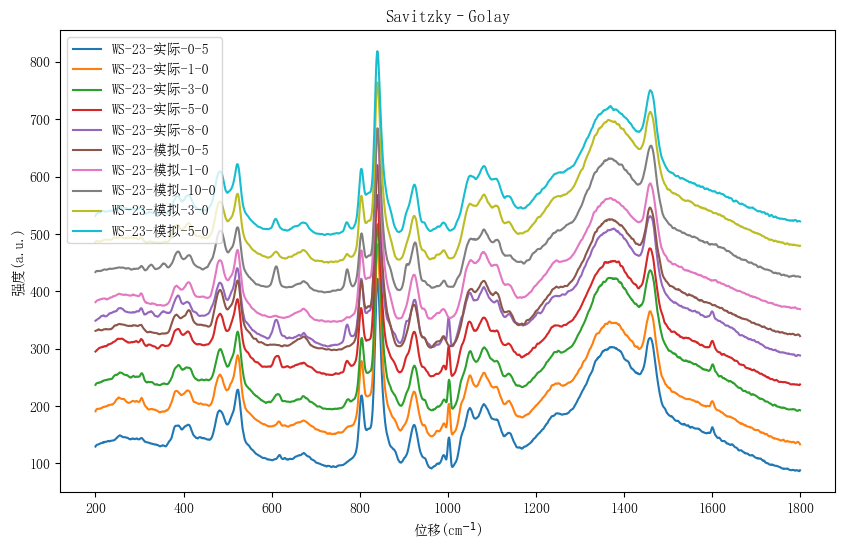

In [16]:
# 画出平滑后的 8 条光谱：labels 用 result 的 class 列（即文件名）作为图例
plot_spectra(x, ys_sg, 'Savitzky–Golay', labels=result.iloc[:, -2], dy=50)

# 步骤4：基线校正
直接使用自适应重加权惩罚最小二乘法（airPLS）进行基线化。**实际pybaselines里的Baseline的airpls方法并不友好，其输入的y只能是1d数组。**
## 4.1 先平滑再基线

In [32]:
# 对平滑后的光谱逐条做 airPLS 基线校正——"先平滑再基线"的顺序（对应 4.1）
ys_airpls = airpls_baseline(ys_sg)

可视化经自适应重加权惩罚最小二乘法基线校正后的拉曼光谱（只show第一行数据）

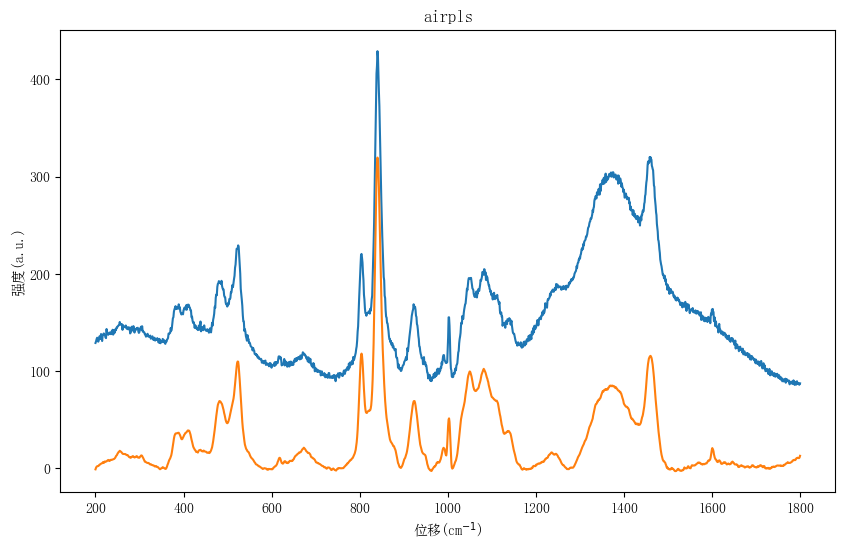

In [33]:
# 只给出第一行的原始数据与其修正后的数据
# [ys[0], ys_airpls[0]] 把"第 1 条原始光谱"与"第 1 条基线校正后的光谱"放在一起对比
ysn = [ys[0] ,ys_airpls[0]]   # 只给出第一行的原始数据与其修正后的数据
# dy=0 表示不偏移，两条线画在同一坐标系里，直观看基线校正的效果
plot_spectra(x, ysn, 'airpls', dy=0)

# 4.2 先基线再平滑

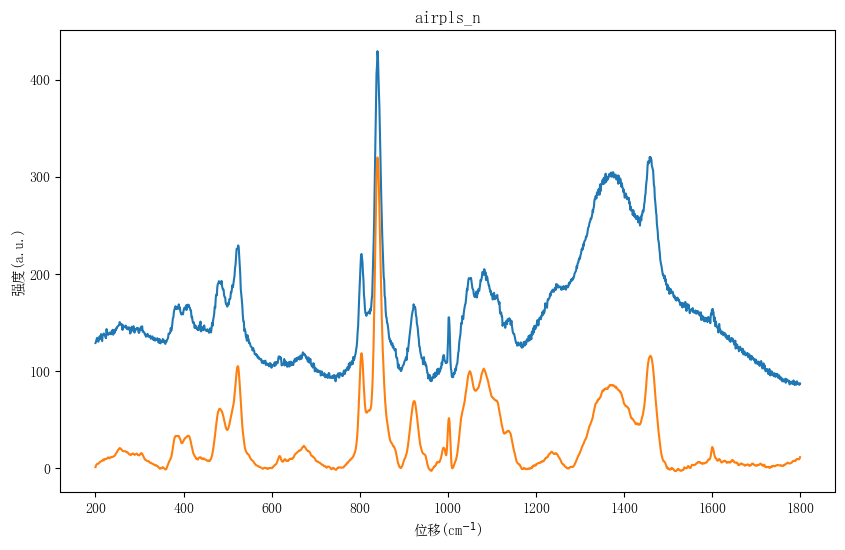

In [34]:
# 4.2"先基线再平滑"：先对原始光谱做基线校正，再做平滑（顺序与 4.1 相反）
ys_airpls_n =  sg_smooth(airpls_baseline(ys))
# 同样取第 1 条光谱做前后对比
ysn = [ys[0] ,ys_airpls_n[0]]
plot_spectra(x, ysn, 'airpls_n', dy=0)

**4.1与4.2，此处的图并不能说明优劣。需要在实际有前处理时，试验。**

# 4.3 画出前N个预处理好的数据

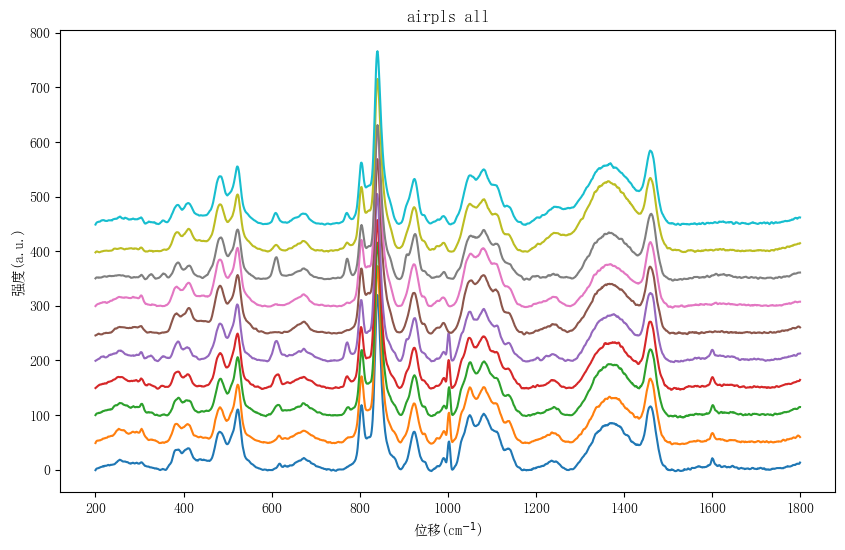

In [28]:
# 把 8 条预处理完成的全部光谱画出（dy=50 错开显示，避免重叠）
plot_spectra(x, ys_airpls_n, 'airpls all', dy=50)

# 步骤5：标准化及归一化

### 为什么要归一化？
不同样品测得的绝对强度可能相差好几倍（受激光功率、样品量、聚焦位置等影响）。归一化把每条光谱各自缩放到 0~1 之间，只保留"峰的相对形状"，让不同样品可以放在同一尺度上比较——这也是把光谱送入机器学习模型之前的常见一步。
观察输出图：8 条曲线的高度都在 0~1 内；因为最大值变成了 1，错开偏移量也相应改小为 0.2。

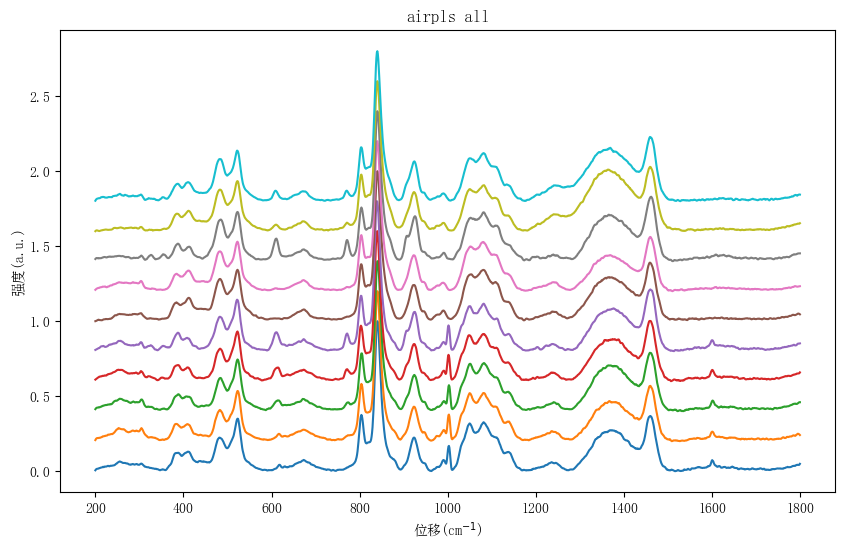

In [30]:
# 再次导入 numpy（保证本格可独立运行）
import numpy as np
# 导入 minmax_scale 归一化工具
from sklearn.preprocessing import minmax_scale
# 归一化：把每条光谱各自缩放到 0~1 之间；axis=1 表示"按行"缩放（每条光谱独立进行）
# 目的：不同样品的绝对强度可能差好几倍，归一化后只比"峰的相对形状"，样品之间才可比，也适合喂给机器学习模型
ys_final = minmax_scale(ys_airpls_n, feature_range=(0, 1), axis=1, copy=True)
# 此处dy=0.2 是因为归一化缩放至最大值为1，因此偏移0.2才合适
plot_spectra(x, ys_final, 'airpls all', dy=0.2)  # 此处dy=0.2 是因为归一化缩放至最大值为1，因此偏移0.2才合适